<a href="https://colab.research.google.com/github/erlianwardana/Repository/blob/main/Prak8_MatkompR1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# Bagian 1: Import library dasar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import math

# Tampilkan grafik langsung di notebook
%matplotlib inline

# Load file Excel
file_path = 'data_produksi_padi.xlsx'
df = pd.read_excel(file_path)
df

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,Data Luas Panen dan Produksi Padi di Jawa Teng...,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,TAHUN,SUBROUND,PRODUKSI PADI (ton),LUAS PANEN (ha)
3,2006,Jan-Apr,4247167,804889
4,NaN,Mei-Ags,3389720.536,662881
5,NaN,Sep-Des,1092402.616,204545
6,2007,Jan-Apr,3381250,629386
7,NaN,Mei-Ags,3790753,725516
8,NaN,Sep-Des,1444852,259196
9,2008,Jan-Apr,4393479,802573


In [16]:
# Bagian 2 (fix): Bersihkan dan rapikan data

# Membaca ulang file dengan header di baris ke-4
df = pd.read_excel(file_path, skiprows=3)

# Menghapus baris yang kolom 'TAHUN' kosong atau bukan angka
df = df[pd.to_numeric(df['TAHUN'], errors='coerce').notnull()]

# Ubah tipe data tahun ke integer
df['TAHUN'] = df['TAHUN'].astype(int)

# Peta subround ke bulan representatif
subround_to_month = {
    'Jan-Apr': '02',
    'Mei-Ags': '06',
    'Sep-Des': '10'
}

# Menambahkan kolom tanggal (ambil bulan tengah subround)
df['BULAN'] = df['SUBROUND'].map(subround_to_month)
df['TANGGAL'] = pd.to_datetime(df['TAHUN'].astype(str) + '-' + df['BULAN'] + '-01', errors='coerce')

# Memilih kolom penting
df_clean = df[['TANGGAL', 'PRODUKSI PADI (ton)', 'LUAS PANEN (ha)']].copy()
df_clean.columns = ['Tanggal', 'Produksi', 'LuasPanen']

# Memastikan kolom numerik
df_clean['Produksi'] = pd.to_numeric(df_clean['Produksi'], errors='coerce')
df_clean['LuasPanen'] = pd.to_numeric(df_clean['LuasPanen'], errors='coerce')

# Set index ke tanggal
df_clean.set_index('Tanggal', inplace=True)

# Menampilkan seluruh data pembersihan
df_clean

,Produksi,LuasPanen
Tanggal,,
2006-02-01,4.247167e+06,804889.0
2007-02-01,3.381250e+06,629386.0
2008-02-01,4.393479e+06,802573.0
2009-02-01,4.560509e+06,822497.0
2010-02-01,4.564766e+06,804684.0
2011-02-01,4.886381e+06,864882.0
2012-02-01,5.031729e+06,845625.0
2013-02-01,5.018464e+06,864313.0
2014-02-01,4.444493e+06,825965.0


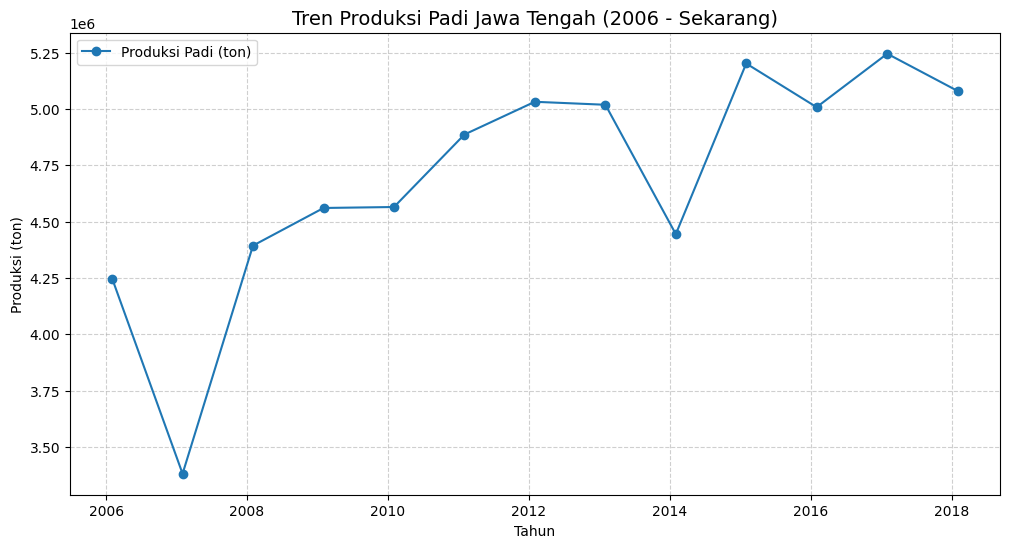

In [17]:
# Bagian 3: Visualisasi tren produksi padi

plt.figure(figsize=(12,6))
plt.plot(df_clean.index, df_clean['Produksi'], marker='o', linestyle='-', label='Produksi Padi (ton)')
plt.title('Tren Produksi Padi Jawa Tengah (2006 - Sekarang)', fontsize=14)
plt.xlabel('Tahun')
plt.ylabel('Produksi (ton)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [18]:
# Bagian 4: Uji Stasioneritas Data (Augmented Dickey-Fuller Test)

# Menampilkan hasil uji ADF
def adf_test(series):
    result = adfuller(series.dropna(), autolag='AIC')
    print('Statistik ADF:', result[0])
    print('p-value:', result[1])
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'   {key}: {value:.3f}')
    if result[1] <= 0.05:
        print('\n✅ Data stasioner (tolak H0)')
    else:
        print('\n❌ Data tidak stasioner (gagal tolak H0)')

# Jalankan uji ADF
print("Uji Stasioneritas Produksi Padi:")
adf_test(df_clean['Produksi'])

Uji Stasioneritas Produksi Padi:
Statistik ADF: -1.825498873032638
p-value: 0.3678776959773722
Critical Values:
   1%: -4.138
   5%: -3.155
   10%: -2.714

❌ Data tidak stasioner (gagal tolak H0)


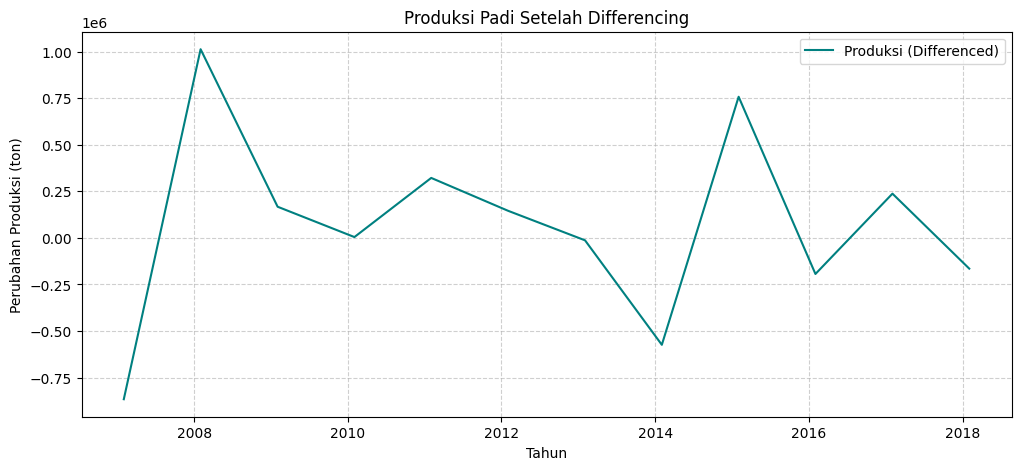

Uji Stasioneritas Setelah Differencing:
Statistik ADF: -7.088918026930278
p-value: 4.4628055299975607e-10
Critical Values:
   1%: -4.223
   5%: -3.189
   10%: -2.730

✅ Data stasioner (tolak H0)


In [19]:
# Bagian 5: Differencing untuk membuat data stasioner
df_diff = df_clean['Produksi'].diff().dropna()

plt.figure(figsize=(12,5))
plt.plot(df_diff, color='teal', label='Produksi (Differenced)')
plt.title('Produksi Padi Setelah Differencing')
plt.xlabel('Tahun')
plt.ylabel('Perubahan Produksi (ton)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Uji ADF ulang pada data yang sudah di-differencing
print("Uji Stasioneritas Setelah Differencing:")
adf_test(df_diff)

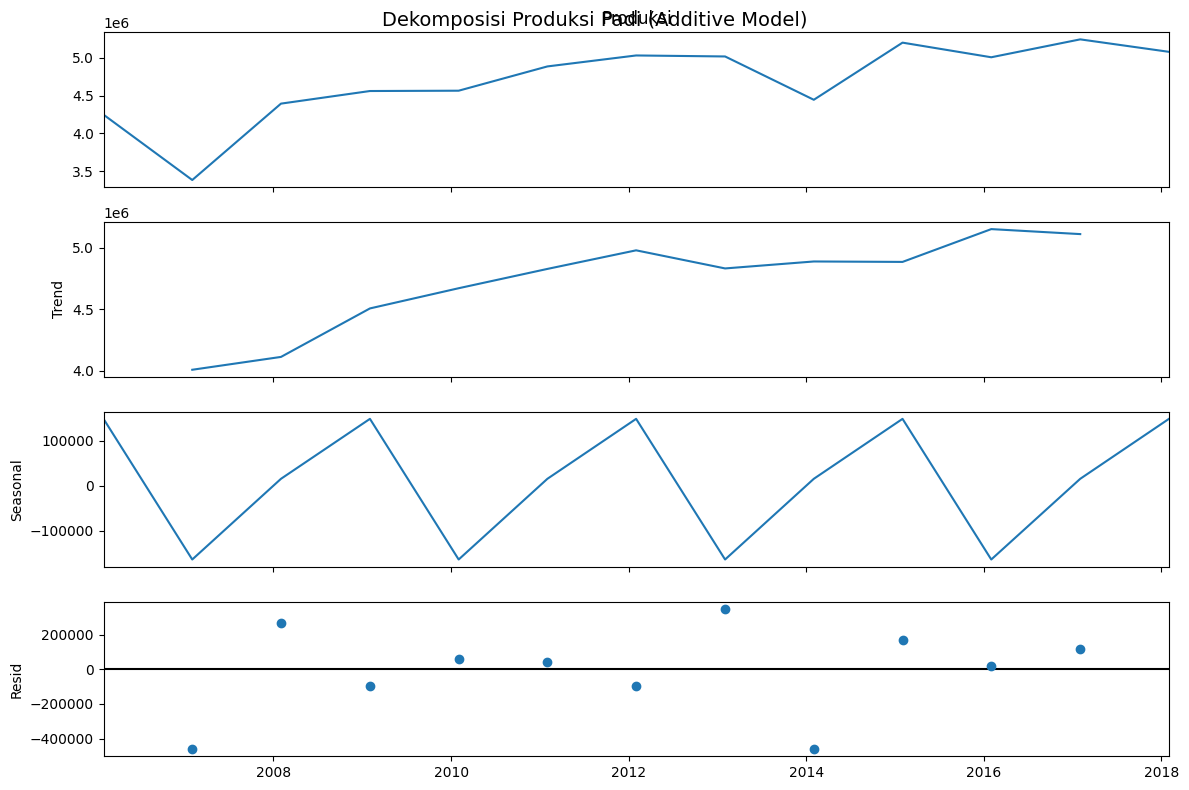

In [20]:
# Bagian 6: Dekomposisi (Trend, Seasonal, Residual)
decompose_result = seasonal_decompose(df_clean['Produksi'], model='additive', period=3)

plt.rcParams.update({'figure.figsize': (12,8)})
decompose_result.plot()
plt.suptitle('Dekomposisi Produksi Padi (Additive Model)', fontsize=14)
plt.show()

In [21]:
# Bagian 7: Pemodelan ARIMA
p, d, q = 1, 1, 1

model = ARIMA(df_clean['Produksi'], order=(p,d,q))
model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:               Produksi   No. Observations:                   13
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -170.515
Date:                Fri, 07 Nov 2025   AIC                            347.029
Time:                        07:18:36   BIC                            348.484
Sample:                    02-01-2006   HQIC                           346.491
                         - 02-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5237      0.225     -2.323      0.020      -0.966      -0.082
ma.L1          0.3094      0.358      0.865      0.387      -0.392       1.011
sigma2       1.02e+11   1.78e-12   5.73e+22      0.0

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-FEB will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-FEB will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-FEB will be used.
  self._init_dates(dates, freq)


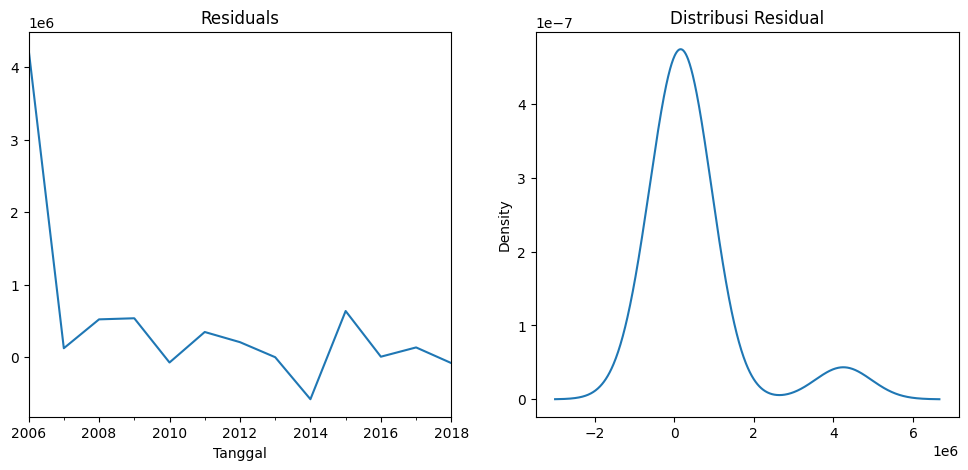

Mean Absolute Error: 270584.26882679603
Root Mean Squared Error: 354581.58544978296


In [22]:
# Bagian 8: Diagnostik Model
residuals = model_fit.resid

fig, ax = plt.subplots(1, 2, figsize=(12,5))
residuals.plot(title="Residuals", ax=ax[0])
residuals.plot(kind='kde', title='Distribusi Residual', ax=ax[1])
plt.show()

# Statistik error
print("Mean Absolute Error:", mean_absolute_error(df_clean['Produksi'][1:], model_fit.fittedvalues[1:]))
print("Root Mean Squared Error:", math.sqrt(mean_squared_error(df_clean['Produksi'][1:], model_fit.fittedvalues[1:])))

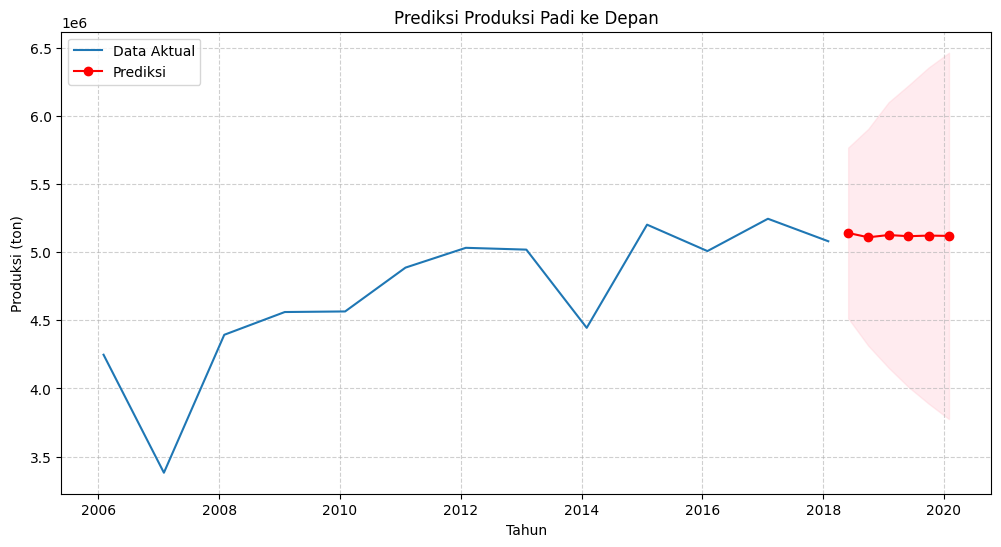

,Tanggal,Prediksi,Lower_CI,Upper_CI
2019-02-01,2018-06-01,5.140869e+06,4.514972e+06,5.766767e+06
2020-02-01,2018-10-01,5.108912e+06,4.312954e+06,5.904870e+06
2021-02-01,2019-02-01,5.125649e+06,4.151282e+06,6.100016e+06
2022-02-01,2019-06-01,5.116883e+06,4.009984e+06,6.223782e+06
2023-02-01,2019-10-01,5.121474e+06,3.887912e+06,6.355036e+06
2024-02-01,2020-02-01,5.119070e+06,3.774735e+06,6.463404e+06


In [23]:
# Bagian 9: Prediksi ke Depan
n_periods = 6  # jumlah periode ke depan
forecast = model_fit.get_forecast(steps=n_periods)
forecast_index = pd.date_range(df_clean.index[-1], periods=n_periods+1, freq='4MS')[1:]

# Membuat DataFrame hasil prediksi
forecast_df = pd.DataFrame({
    'Tanggal': forecast_index,
    'Prediksi': forecast.predicted_mean,
    'Lower_CI': forecast.conf_int().iloc[:,0],
    'Upper_CI': forecast.conf_int().iloc[:,1]
})

plt.figure(figsize=(12,6))
plt.plot(df_clean.index, df_clean['Produksi'], label='Data Aktual')
plt.plot(forecast_df['Tanggal'], forecast_df['Prediksi'], color='red', marker='o', label='Prediksi')
plt.fill_between(forecast_df['Tanggal'], forecast_df['Lower_CI'], forecast_df['Upper_CI'], color='pink', alpha=0.3)
plt.title('Prediksi Produksi Padi ke Depan')
plt.xlabel('Tahun')
plt.ylabel('Produksi (ton)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

forecast_df